# Training Ulang SVM + TF-IDF: Severity **per Kategori**

Notebook ini melatih ulang baseline SVM supaya severity diprediksi **per pasangan (review, kategori)**, sama seperti
granularitas model Transformer. Dengan begitu perbandingan ML vs Transformer untuk severity menjadi apple-to-apple.

**Yang berubah dari baseline lama**

| | Baseline lama | Notebook ini |
|---|---|---|
| Unit severity | 1 label per review (severity tertinggi) | 1 label per **(review, kategori)** |
| Target | `highest_severity` lintas kategori | `severity_Issue` pada baris `(review_id, category_Issue)` |
| Issue classifier | OneVsRest LinearSVC (10 kelas) | **sama**, hanya split diambil dari file split resmi |

**Aturan penting**
- Split memakai **split Transformer** (`review_id_split_transformer.csv`, salinan `review_id_split.csv` milik IndoBERT/mBERT/XLM-R yang ketiganya identik), supaya test set SVM sama persis dengan test set Transformer.
- Semua tuning hanya memakai train -> validation. Test hanya dipakai sekali di akhir.
- Kategori `OTHER` dipakai untuk issue **dan** severity (`INCLUDE_OTHER_IN_SEVERITY = True`), karena file prediksi severity Transformer juga memuat `OTHER` (1.854 pasangan di test). `OTHER` hanya punya 22 sampel, jadi hasilnya per kategori tidak stabil.

## 0. Modul model (dipakai juga oleh `app.py`)
Cell ini menulis `severity_percat.py` ke folder kerja. File yang sama harus ditaruh di folder `app.py` agar `joblib` bisa memuat model.

In [3]:
%%writefile severity_percat.py
"""Model severity per (review, kategori) berbasis LinearSVC + TF-IDF.

File ini dipakai bersama oleh notebook training DAN app.py agar joblib bisa
me-load model yang sama (class harus bisa di-import dengan nama modul yang sama).

mode:
  shared       : satu LinearSVC; fitur = TF-IDF teks + one-hot kategori
  augmented    : shared + salinan TF-IDF khusus tiap kategori (feature augmentation)
  per_category : satu LinearSVC terpisah per kategori; kategori yang datanya terlalu
                 sedikit / hanya 1 kelas memakai model shared sebagai fallback
"""
import numpy as np
import scipy.sparse as sp
from sklearn.svm import LinearSVC

SEVERITY_ORDER = ["LOW", "MEDIUM", "HIGH", "BLOCKER"]


class CategorySeverityModel:
    def __init__(self, mode="augmented", C=1.0, class_weight=None, categories=None,
                 min_samples=30, seed=42):
        self.mode = mode
        self.C = C
        self.class_weight = class_weight
        self.categories = list(categories) if categories is not None else None
        self.min_samples = min_samples
        self.seed = seed

    # ---------- fitur ----------
    def _svc(self):
        return LinearSVC(C=self.C, class_weight=self.class_weight,
                         random_state=self.seed, max_iter=10000, dual="auto")

    def _onehot(self, cats):
        idx = {c: i for i, c in enumerate(self.categories)}
        rows, cols = [], []
        for r, c in enumerate(cats):
            if c in idx:
                rows.append(r)
                cols.append(idx[c])
        return sp.csr_matrix((np.ones(len(rows), dtype=np.float32), (rows, cols)),
                             shape=(len(cats), len(self.categories)))

    def _features(self, X, cats):
        cats = np.asarray(cats)
        if self.mode == "shared":
            return sp.hstack([X, self._onehot(cats)], format="csr")
        if self.mode == "augmented":
            blocks = [X, self._onehot(cats)]
            for c in self.categories:
                blocks.append(sp.diags((cats == c).astype(np.float32)) @ X)
            return sp.hstack(blocks, format="csr")
        raise ValueError(self.mode)

    # ---------- training ----------
    def fit(self, X, cats, y):
        cats, y = np.asarray(cats), np.asarray(y)
        if self.categories is None:
            self.categories = sorted(set(cats))
        if self.mode in ("shared", "augmented"):
            self.model_ = self._svc().fit(self._features(X, cats), y)
            self.classes_ = self.model_.classes_
            return self
        # per_category
        self.global_ = self._svc().fit(self._features_shared(X, cats), y)
        self.classes_ = self.global_.classes_
        self.cat_models_, self.cat_info_ = {}, {}
        for c in self.categories:
            m = cats == c
            labels = np.unique(y[m])
            if m.sum() == 0:
                self.cat_info_[c] = "fallback_global (tidak ada data)"
            elif len(labels) == 1:
                self.cat_models_[c] = str(labels[0])
                self.cat_info_[c] = f"konstan={labels[0]} (hanya 1 kelas)"
            elif m.sum() < self.min_samples:
                self.cat_info_[c] = f"fallback_global (n={int(m.sum())} < {self.min_samples})"
            else:
                self.cat_models_[c] = self._svc().fit(X[m], y[m])
                self.cat_info_[c] = f"model sendiri (n={int(m.sum())})"
        return self

    def _features_shared(self, X, cats):
        return sp.hstack([X, self._onehot(cats)], format="csr")

    # ---------- prediksi ----------
    def predict(self, X, cats):
        return self.predict_with_margin(X, cats)[0]

    def predict_with_margin(self, X, cats):
        """Return (label, margin_kelas_terpilih). Margin = decision_function (bukan probabilitas)."""
        cats = np.asarray(cats)
        n = X.shape[0]
        labels = np.empty(n, dtype=object)
        margins = np.zeros(n, dtype=float)
        if self.mode in ("shared", "augmented"):
            dec = self._decision(self.model_, self._features(X, cats))
            best = dec.argmax(1)
            labels[:] = self.model_.classes_[best]
            margins[:] = dec[np.arange(n), best]
            return labels, margins
        dec_g = self._decision(self.global_, self._features_shared(X, cats))
        best = dec_g.argmax(1)
        labels[:] = self.global_.classes_[best]
        margins[:] = dec_g[np.arange(n), best]
        for c, m in self.cat_models_.items():
            mask = cats == c
            if not mask.any():
                continue
            if isinstance(m, str):
                labels[mask] = m
                margins[mask] = 0.0
            else:
                d = self._decision(m, X[mask])
                b = d.argmax(1)
                labels[mask] = m.classes_[b]
                margins[mask] = d[np.arange(d.shape[0]), b]
        return labels, margins

    @staticmethod
    def _decision(model, X):
        d = model.decision_function(X)
        if d.ndim == 1:  # biner: kolom ke-0 = kelas pertama, kolom ke-1 = kelas kedua
            d = np.column_stack([-d, d])
        return d

Overwriting severity_percat.py


## 1. Import dan konfigurasi

In [5]:
from pathlib import Path
import json, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from IPython.display import display
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import MultiLabelBinarizer
from sklearn.multiclass import OneVsRestClassifier
from sklearn.svm import LinearSVC
from sklearn.metrics import (accuracy_score, f1_score, precision_score, recall_score, hamming_loss,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay)

from severity_percat import CategorySeverityModel, SEVERITY_ORDER

SEED = 42
SEVERITY_LABELS = SEVERITY_ORDER                       # LOW < MEDIUM < HIGH < BLOCKER
SEV_RANK = {l: i for i, l in enumerate(SEVERITY_LABELS)}
INCLUDE_OTHER_IN_SEVERITY = True                       # True = sama dengan Transformer (severity juga untuk OTHER)
OUTPUT_DIR = Path("svm_tfidf_percat_outputs"); OUTPUT_DIR.mkdir(exist_ok=True)

def find(*names):
    for n in names:
        if Path(n).exists(): return Path(n)
    raise FileNotFoundError(f"Tidak ditemukan: {names}. Taruh file di folder notebook.")

RAW_PATH   = find("alfagift_issue_labeled_merged.csv", "alfagift_issue_labeled_merged(1).csv")
REV_PATH   = find("review_level_modeling_dataset.csv")
SPLIT_PATH = find("review_id_split_transformer.csv")   # salin review_id_split.csv milik Transformer, lalu ganti namanya
print(RAW_PATH, REV_PATH, SPLIT_PATH, sep="\n")

alfagift_issue_labeled_merged.csv
review_level_modeling_dataset.csv
review_id_split_transformer.csv


## 2. Muat data dan bentuk pasangan `(review, kategori)`

- `review_level_modeling_dataset.csv` -> teks model (`model_text`), kategori per review, severity tertinggi per review.
- `alfagift_issue_labeled_merged.csv` -> severity **per kategori** (satu baris per `review_id` x `category_Issue`).
- `review_id_split_transformer.csv` -> penentu train / validation / test (split yang sama dengan Transformer).

In [7]:
raw = pd.read_csv(RAW_PATH, low_memory=False)
rl  = pd.read_csv(REV_PATH)
spl = pd.read_csv(SPLIT_PATH)

for c in ["category_Issue", "severity_Issue"]:
    raw[c] = raw[c].astype("string").str.strip().str.upper()
    raw.loc[raw[c].eq(""), c] = pd.NA

n_before = len(raw)
raw = raw.dropna(subset=["review_id", "category_Issue", "severity_Issue"]).copy()
print(f"Baris berlabel lengkap: {len(raw):,} dari {n_before:,} (baris tanpa label dibuang)")

# --- validasi file split ---
assert spl["review_id"].is_unique, "review_id duplikat di file split"
assert set(spl["review_id"]) == set(rl["review_id"]), "review_id split != review-level dataset"
assert set(raw["review_id"]) <= set(spl["review_id"]), "ada review berlabel yang tidak ada di split"
assert not raw.duplicated(["review_id", "category_Issue"]).any(), "ada pasangan (review, kategori) ganda"

rl = rl.merge(spl, on="review_id", how="left", validate="one_to_one")
rl["cats"] = rl["categories"].map(json.loads)
rl["model_text"] = rl["model_text"].fillna("").astype(str).str.strip()
print("Ukuran split (review):"); display(rl["split"].value_counts().to_frame("n_review"))

# --- pasangan (review, kategori) untuk severity ---
pairs = raw.rename(columns={"category_Issue": "category", "severity_Issue": "severity"})[["review_id", "category", "severity"]]
pairs = pairs.merge(spl, on="review_id", how="left")
if not INCLUDE_OTHER_IN_SEVERITY:
    pairs = pairs[pairs["category"] != "OTHER"]
pairs = pairs.reset_index(drop=True)
assert set(pairs["severity"]) <= set(SEVERITY_LABELS)

# severity tertinggi per review (target model "lama" dan acuan evaluasi tingkat review),
# dihitung dari pasangan yang sama agar konsisten dengan INCLUDE_OTHER_IN_SEVERITY
rev_target = pairs.groupby("review_id")["severity"].agg(lambda s: max(s, key=SEV_RANK.get))
rl["severity"] = rl["review_id"].map(rev_target)

# cek opsional: review test pada split ini harus sama dengan review di file prediksi Transformer
test_ids = set(rl.loc[rl["split"] == "test", "review_id"].astype(str))
for p in sorted(Path("results").glob("*/*_issue_test_predictions.csv")):
    if "svm" in p.parent.name.lower():
        continue
    ids = set(pd.read_csv(p, usecols=["review_id"], encoding="utf-8-sig")["review_id"].astype(str))
    print(f"{p.parent.name:10s} test set sama dengan split ini:", ids == test_ids)

ISSUE_LABELS = sorted({c for cats in rl["cats"] for c in cats})
SEV_CATEGORIES = sorted(pairs["category"].unique())
print("Kategori issue:", ISSUE_LABELS)
print("Kategori severity:", SEV_CATEGORIES)

print("Jumlah pasangan (review, kategori) per split:")
display(pairs["split"].value_counts().to_frame("n_pairs"))
print("Distribusi severity per kategori (train):")
display(pd.crosstab(pairs.loc[pairs.split == "train", "category"], pairs.loc[pairs.split == "train", "severity"])
        .reindex(columns=SEVERITY_LABELS, fill_value=0))

Baris berlabel lengkap: 18,508 dari 18,531 (baris tanpa label dibuang)
Ukuran split (review):


,n_review
split,
train,11515
test,1439
validation,1419


Kategori issue: ['ACCOUNT', 'INSTALL_UPDATE', 'LOCATION', 'ORDER', 'OTHER', 'PAYMENT', 'RECEIPT_NOTIF', 'SYSTEM', 'UI_FEATURE', 'VOUCHER']
Kategori severity: ['ACCOUNT', 'INSTALL_UPDATE', 'LOCATION', 'ORDER', 'OTHER', 'PAYMENT', 'RECEIPT_NOTIF', 'SYSTEM', 'UI_FEATURE', 'VOUCHER']
Jumlah pasangan (review, kategori) per split:


,n_pairs
split,
train,14801
test,1854
validation,1853


Distribusi severity per kategori (train):


severity,LOW,MEDIUM,HIGH,BLOCKER
category,,,,
ACCOUNT,0,85,255,2247
INSTALL_UPDATE,267,5,26,625
LOCATION,0,1,167,76
ORDER,5,1393,631,167
OTHER,0,0,10,8
PAYMENT,3,384,346,574
RECEIPT_NOTIF,3,620,8,6
SYSTEM,34,102,2733,1613
UI_FEATURE,466,10,7,5


## 3. Catatan penting tentang data

Pada data ini severity **sangat bergantung pada kategori** (misalnya `VOUCHER` hampir selalu `MEDIUM`, `ACCOUNT` hampir selalu `BLOCKER`).
Karena itu notebook ini juga menghitung baseline **"tebak severity mayoritas per kategori"**. Model severity yang baik harus
mengalahkan baseline itu, kalau tidak berarti teks belum memberi informasi tambahan di luar kategori.

## 4. Helper TF-IDF dan metrik

In [10]:
TFIDF_KW = dict(lowercase=True, ngram_range=(1, 2), min_df=2, max_df=0.95,
                sublinear_tf=True, max_features=300_000, dtype=np.float32)

def pair_matrix(vec, splits):
    """Matriks TF-IDF per pasangan (baris review diulang untuk tiap kategorinya)."""
    revs = rl[rl["split"].isin(splits)].reset_index(drop=True)
    Xr = vec.transform(revs["model_text"])
    rowmap = {rid: i for i, rid in enumerate(revs["review_id"])}
    p = pairs[pairs["split"].isin(splits)].reset_index(drop=True)
    rows = p["review_id"].map(rowmap).to_numpy()
    return Xr[rows], p["category"].to_numpy(), p["severity"].to_numpy(), p

def sev_metrics(y_true, y_pred):
    kw = dict(labels=SEVERITY_LABELS, zero_division=0)
    return {"n": len(y_true),
            "accuracy": accuracy_score(y_true, y_pred),
            "macro_F1": f1_score(y_true, y_pred, average="macro", **kw),
            "weighted_F1": f1_score(y_true, y_pred, average="weighted", **kw),
            "macro_precision": precision_score(y_true, y_pred, average="macro", **kw),
            "macro_recall": recall_score(y_true, y_pred, average="macro", **kw)}

## 5. Tuning di validation (tanpa menyentuh test)

In [12]:
vec_tune = TfidfVectorizer(**TFIDF_KW).fit(rl.loc[rl.split == "train", "model_text"])
Xtr_p, ctr, ytr, ptr = pair_matrix(vec_tune, ["train"])
Xva_p, cva, yva, pva = pair_matrix(vec_tune, ["validation"])
print("Pair train:", Xtr_p.shape, "| Pair validation:", Xva_p.shape)

MODES = ["shared", "augmented", "per_category"]
C_GRID = [0.05, 0.1, 0.5, 1.0, 2.0, 5.0]
CW_GRID = [None, "balanced"]

rows, best = [], {"macro_F1": -1}
t0 = time.time()
for mode in MODES:
    for cw in CW_GRID:
        for C in C_GRID:
            m = CategorySeverityModel(mode=mode, C=C, class_weight=cw, categories=SEV_CATEGORIES, seed=SEED).fit(Xtr_p, ctr, ytr)
            r = sev_metrics(yva, m.predict(Xva_p, cva))
            rows.append({"mode": mode, "C": C, "class_weight": str(cw), "val_macro_F1": r["macro_F1"],
                         "val_weighted_F1": r["weighted_F1"], "val_accuracy": r["accuracy"]})
            if r["macro_F1"] > best["macro_F1"]:
                best = {"macro_F1": r["macro_F1"], "mode": mode, "C": C, "class_weight": cw}
print(f"Selesai dalam {time.time()-t0:.0f} detik")
tune_df = pd.DataFrame(rows).sort_values("val_macro_F1", ascending=False)
display(tune_df.head(10).round(4))
print("Terbaik per mode:")
display(tune_df.groupby("mode").head(1).round(4))
print("\nKonfigurasi severity terpilih:", best)

Pair train: (14801, 27129) | Pair validation: (1853, 27129)
Selesai dalam 17 detik


,mode,C,class_weight,val_macro_F1,val_weighted_F1,val_accuracy
21,augmented,1.0,balanced,0.8979,0.8956,0.8958
20,augmented,0.5,balanced,0.8970,0.8961,0.8964
15,augmented,1.0,None,0.8953,0.8945,0.8948
16,augmented,2.0,None,0.8952,0.8913,0.8915
22,augmented,2.0,balanced,0.8940,0.8908,0.8910
17,augmented,5.0,None,0.8937,0.8892,0.8894
14,augmented,0.5,None,0.8930,0.8934,0.8937
2,shared,0.5,None,0.8923,0.8911,0.8915
13,augmented,0.1,None,0.8921,0.8922,0.8926
8,shared,0.5,balanced,0.8920,0.8912,0.8915


Terbaik per mode:


,mode,C,class_weight,val_macro_F1,val_weighted_F1,val_accuracy
21,augmented,1.0,balanced,0.8979,0.8956,0.8958
2,shared,0.5,None,0.8923,0.8911,0.8915
32,per_category,0.5,balanced,0.8917,0.8912,0.8915



Konfigurasi severity terpilih: {'macro_F1': 0.8978699541561198, 'mode': 'augmented', 'C': 1.0, 'class_weight': 'balanced'}


In [13]:
# Tuning issue classifier (OneVsRest, 10 kelas) pada split yang sama
revs_tr = rl[rl.split == "train"].reset_index(drop=True)
revs_va = rl[rl.split == "validation"].reset_index(drop=True)
mlb = MultiLabelBinarizer(classes=ISSUE_LABELS)
Yi_tr = mlb.fit_transform(revs_tr["cats"]); Yi_va = mlb.transform(revs_va["cats"])
Xi_tr = vec_tune.transform(revs_tr["model_text"]); Xi_va = vec_tune.transform(revs_va["model_text"])

issue_rows, best_issue = [], {"macro_F1": -1}
for cw in CW_GRID:
    for C in [0.1, 0.5, 1.0, 2.0, 5.0]:
        clf = OneVsRestClassifier(LinearSVC(C=C, class_weight=cw, random_state=SEED, max_iter=10000, dual="auto")).fit(Xi_tr, Yi_tr)
        f1 = f1_score(Yi_va, clf.predict(Xi_va), average="macro", zero_division=0)
        issue_rows.append({"C": C, "class_weight": str(cw), "val_macro_F1": f1})
        if f1 > best_issue["macro_F1"]: best_issue = {"macro_F1": f1, "C": C, "class_weight": cw}
display(pd.DataFrame(issue_rows).sort_values("val_macro_F1", ascending=False).round(4).head(5))
print("Konfigurasi issue terpilih:", best_issue)

,C,class_weight,val_macro_F1
5,0.1,balanced,0.7601
3,2.0,None,0.7397
4,5.0,None,0.7394
9,5.0,balanced,0.7344
8,2.0,balanced,0.7341


Konfigurasi issue terpilih: {'macro_F1': 0.7601355944552834, 'C': 0.1, 'class_weight': 'balanced'}


## 6. Training final (train + validation) dan prediksi test

In [15]:
final_vec = TfidfVectorizer(**TFIDF_KW).fit(rl.loc[rl.split.isin(["train", "validation"]), "model_text"])

# --- severity per kategori ---
Xtv_p, ctv, ytv, _ = pair_matrix(final_vec, ["train", "validation"])
Xte_p, cte, yte, pte = pair_matrix(final_vec, ["test"])
sev_model = CategorySeverityModel(mode=best["mode"], C=best["C"], class_weight=best["class_weight"],
                                  categories=SEV_CATEGORIES, seed=SEED).fit(Xtv_p, ctv, ytv)
pred_te, margin_te = sev_model.predict_with_margin(Xte_p, cte)
if best["mode"] == "per_category":
    print("Status model per kategori:"); display(pd.Series(sev_model.cat_info_).to_frame("status"))

# --- issue classifier ---
revs_tv = rl[rl.split.isin(["train", "validation"])].reset_index(drop=True)
revs_te = rl[rl.split == "test"].reset_index(drop=True)
mlb = MultiLabelBinarizer(classes=ISSUE_LABELS)
Yi_tv = mlb.fit_transform(revs_tv["cats"]); Yi_te = mlb.transform(revs_te["cats"])
Xi_tv = final_vec.transform(revs_tv["model_text"]); Xi_te = final_vec.transform(revs_te["model_text"])
issue_model = OneVsRestClassifier(LinearSVC(C=best_issue["C"], class_weight=best_issue["class_weight"],
                                            random_state=SEED, max_iter=10000, dual="auto")).fit(Xi_tv, Yi_tv)
Yi_pred = issue_model.predict(Xi_te)
issue_metrics = {
    "macro_F1": f1_score(Yi_te, Yi_pred, average="macro", zero_division=0),
    "micro_F1": f1_score(Yi_te, Yi_pred, average="micro", zero_division=0),
    "weighted_F1": f1_score(Yi_te, Yi_pred, average="weighted", zero_division=0),
    "macro_precision": precision_score(Yi_te, Yi_pred, average="macro", zero_division=0),
    "macro_recall": recall_score(Yi_te, Yi_pred, average="macro", zero_division=0),
    "hamming_loss": hamming_loss(Yi_te, Yi_pred),
    "subset_accuracy": accuracy_score(Yi_te, Yi_pred),
}
print("Issue (test):", {k: round(v, 4) for k, v in issue_metrics.items()})

Issue (test): {'macro_F1': 0.7189, 'micro_F1': 0.8547, 'weighted_F1': 0.8611, 'macro_precision': 0.6635, 'macro_recall': 0.7954, 'hamming_loss': 0.0396, 'subset_accuracy': 0.6803}


## 7. Evaluasi utama: severity per kategori (test)

Dievaluasi pada pasangan `(review, kategori)` **ground truth** di test set, agar kemampuan severity diukur terpisah
dari kesalahan issue classifier. Ini yang dibandingkan dengan Transformer.

Severity per kategori, test (n=1,854 pasangan):


,nilai
n,1854.0000
accuracy,0.9002
macro_F1,0.9030
weighted_F1,0.8997
macro_precision,0.9079
macro_recall,0.8994


,precision,recall,f1-score,support
LOW,0.9320,0.9057,0.9187,106.0000
MEDIUM,0.9034,0.9357,0.9193,560.0000
HIGH,0.9115,0.8311,0.8695,533.0000
BLOCKER,0.8847,0.9252,0.9045,655.0000
accuracy,0.9002,0.9002,0.9002,0.9002
macro avg,0.9079,0.8994,0.9030,1854.0000
weighted avg,0.9008,0.9002,0.8997,1854.0000


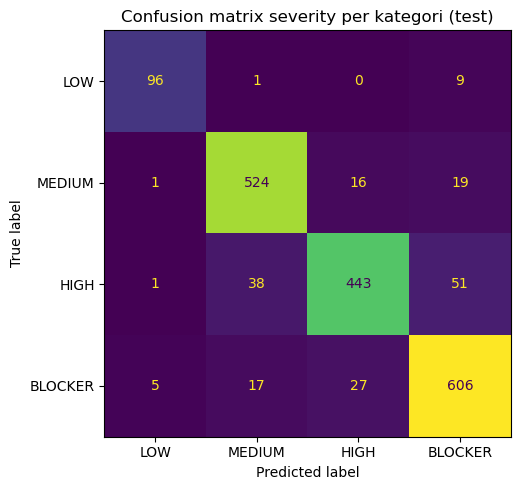

,category,n,accuracy,macro_F1(kelas yang ada)
0,ACCOUNT,324,0.8827,0.6441
1,INSTALL_UPDATE,116,0.9052,0.9301
2,LOCATION,31,0.9032,0.8342
3,ORDER,275,0.8036,0.5582
4,OTHER,2,1.0000,1.0000
5,PAYMENT,164,0.8110,0.5859
6,RECEIPT_NOTIF,80,0.9625,0.4952
7,SYSTEM,561,0.9251,0.7623
8,UI_FEATURE,61,0.9836,0.4959
9,VOUCHER,240,0.9917,0.4979


In [17]:
main_metrics = sev_metrics(yte, pred_te)
print(f"Severity per kategori, test (n={main_metrics['n']:,} pasangan):")
display(pd.DataFrame([main_metrics]).T.rename(columns={0: "nilai"}).round(4))

rep = classification_report(yte, pred_te, labels=SEVERITY_LABELS, target_names=SEVERITY_LABELS, output_dict=True, zero_division=0)
display(pd.DataFrame(rep).T.round(4))

fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay(confusion_matrix(yte, pred_te, labels=SEVERITY_LABELS), display_labels=SEVERITY_LABELS).plot(ax=ax, values_format="d", colorbar=False)
ax.set_title("Confusion matrix severity per kategori (test)"); plt.tight_layout(); plt.show()

by_cat = []
for c in SEV_CATEGORIES:
    m = pte["category"].to_numpy() == c
    if m.sum() == 0: continue
    by_cat.append({"category": c, "n": int(m.sum()), "accuracy": accuracy_score(yte[m], pred_te[m]),
                   "macro_F1(kelas yang ada)": f1_score(yte[m], pred_te[m], average="macro", zero_division=0)})
by_cat_df = pd.DataFrame(by_cat); display(by_cat_df.round(4))

## 8. Sanity check: apakah teks benar-benar membantu?

Baseline tanpa teks: untuk setiap kategori, tebak severity yang paling sering muncul di train+validation.

In [19]:
majority = pd.Series(ytv).groupby(ctv).agg(lambda s: s.value_counts().idxmax()).to_dict()
pred_major = np.array([majority.get(c, "BLOCKER") for c in cte])
major_metrics = sev_metrics(yte, pred_major)
cmp = pd.DataFrame({"Mayoritas per kategori (tanpa teks)": major_metrics, "SVM per kategori (dengan teks)": main_metrics}).T
display(cmp[["accuracy", "macro_F1", "weighted_F1"]].round(4))
if main_metrics["macro_F1"] <= major_metrics["macro_F1"]:
    print("PERINGATAN: model belum mengalahkan baseline mayoritas per kategori pada macro-F1.")

,accuracy,macro_F1,weighted_F1
Mayoritas per kategori (tanpa teks),0.7238,0.7234,0.7230
SVM per kategori (dengan teks),0.9002,0.9030,0.8997


## 9. Perbandingan dengan baseline lama (severity 1 label per review)

Model lama dilatih ulang dengan split yang sama, lalu labelnya disalin ke setiap kategori review. Ini menunjukkan
seberapa besar perubahan dari desain lama ke desain per kategori.

In [21]:
# model lama: review-level, target = severity tertinggi per review
rev_sev = rl.dropna(subset=["severity"])
tr_old = rev_sev[rev_sev.split == "train"]; va_old = rev_sev[rev_sev.split == "validation"]
Xo_tr = vec_tune.transform(tr_old["model_text"]); Xo_va = vec_tune.transform(va_old["model_text"])
best_old = {"f1": -1}
for cw in CW_GRID:
    for C in C_GRID:
        mo = LinearSVC(C=C, class_weight=cw, random_state=SEED, max_iter=10000, dual="auto").fit(Xo_tr, tr_old["severity"])
        f1 = f1_score(va_old["severity"], mo.predict(Xo_va), labels=SEVERITY_LABELS, average="macro", zero_division=0)
        if f1 > best_old["f1"]: best_old = {"f1": f1, "C": C, "class_weight": cw}
tv_old = rev_sev[rev_sev.split.isin(["train", "validation"])]
old_model = LinearSVC(C=best_old["C"], class_weight=best_old["class_weight"], random_state=SEED, max_iter=10000, dual="auto")
old_model.fit(final_vec.transform(tv_old["model_text"]), tv_old["severity"])

# prediksi lama pada pasangan test: label review disalin ke tiap kategori
old_rev_pred = dict(zip(revs_te["review_id"], old_model.predict(Xi_te)))
pred_old_pair = pte["review_id"].map(old_rev_pred).to_numpy()
old_pair_metrics = sev_metrics(yte, pred_old_pair)

cmp2 = pd.DataFrame({"SVM lama (1 severity/review, disalin ke tiap kategori)": old_pair_metrics,
                     "SVM baru (per kategori)": main_metrics}).T
print("Perbandingan pada pasangan (review, kategori) test yang sama:")
display(cmp2[["n", "accuracy", "macro_F1", "weighted_F1"]].round(4))

Perbandingan pada pasangan (review, kategori) test yang sama:


,n,accuracy,macro_F1,weighted_F1
"SVM lama (1 severity/review, disalin ke tiap kategori)",1854.0,0.8285,0.7271,0.8211
SVM baru (per kategori),1854.0,0.9002,0.9030,0.8997


## 10. Evaluasi tingkat review (agregasi = severity tertinggi)

Dipakai kalau Anda ingin membandingkan dengan model yang hanya menghasilkan satu severity per review. Dua versi:
- **Kategori ground truth**: mengukur kemampuan severity saja.
- **Kategori prediksi (end-to-end)**: kesalahan issue ikut terbawa. Review tanpa kategori terprediksi yang punya severity dihitung salah (`NONE`).

In [23]:
def highest(labels):
    return max(labels, key=SEV_RANK.get) if len(labels) else "NONE"

truth_rev = revs_te.dropna(subset=["severity"]).set_index("review_id")["severity"]

# (a) agregasi dari kategori ground truth, pakai model baru
tmp = pte.assign(pred=pred_te)
agg_true = tmp.groupby("review_id")["pred"].agg(lambda s: highest(list(s)))
a = truth_rev.index.intersection(agg_true.index)
rev_true_cat = sev_metrics(truth_rev.loc[a].to_numpy(), agg_true.loc[a].to_numpy())

# (b) end-to-end: kategori diprediksi issue model
pred_cat_lists = [[mlb.classes_[j] for j in np.where(r == 1)[0] if INCLUDE_OTHER_IN_SEVERITY or mlb.classes_[j] != "OTHER"] for r in Yi_pred]
e2e_pairs = pd.DataFrame([(rid, c) for rid, cl in zip(revs_te["review_id"], pred_cat_lists) for c in cl], columns=["review_id", "category"])
rowmap_te = {rid: i for i, rid in enumerate(revs_te["review_id"])}
if len(e2e_pairs):
    Xe = Xi_te[e2e_pairs["review_id"].map(rowmap_te).to_numpy()]
    e2e_pairs["pred"] = sev_model.predict(Xe, e2e_pairs["category"].to_numpy())
    agg_e2e = e2e_pairs.groupby("review_id")["pred"].agg(lambda s: highest(list(s)))
else:
    agg_e2e = pd.Series(dtype=object)
pred_e2e = truth_rev.index.map(lambda r: agg_e2e.get(r, "NONE"))
rev_e2e = sev_metrics(truth_rev.to_numpy(), np.array(pred_e2e))

# (c) model lama (tingkat review asli)
old_rev = pd.Series(old_rev_pred).reindex(truth_rev.index)
rev_old = sev_metrics(truth_rev.to_numpy(), old_rev.to_numpy())

cmp3 = pd.DataFrame({"SVM lama (review-level)": rev_old,
                     "SVM baru, agregasi (kategori ground truth)": rev_true_cat,
                     "SVM baru, agregasi (kategori prediksi, end-to-end)": rev_e2e}).T
print("Severity tingkat review, test:")
display(cmp3[["n", "accuracy", "macro_F1", "weighted_F1"]].round(4))

# (d) end-to-end per pasangan: hanya pasangan yang kategorinya benar-benar terprediksi
if len(e2e_pairs):
    j = e2e_pairs.merge(pte[["review_id", "category", "severity"]], on=["review_id", "category"], how="inner")
    cover = len(j) / len(pte)
    print(f"End-to-end per pasangan: {len(j):,} pasangan tepat-kategori ({cover:.1%} dari {len(pte):,} pasangan test)")
    display(pd.DataFrame([sev_metrics(j["severity"].to_numpy(), j["pred"].to_numpy())]).round(4))

Severity tingkat review, test:


,n,accuracy,macro_F1,weighted_F1
SVM lama (review-level),1439.0,0.8652,0.7634,0.8663
"SVM baru, agregasi (kategori ground truth)",1439.0,0.8937,0.8916,0.8929
"SVM baru, agregasi (kategori prediksi, end-to-end)",1439.0,0.8388,0.7702,0.8479


End-to-end per pasangan: 1,677 pasangan tepat-kategori (90.5% dari 1,854 pasangan test)


,n,accuracy,macro_F1,weighted_F1,macro_precision,macro_recall
0,1677,0.9052,0.9076,0.9047,0.9114,0.9052


## 11. Simpan model dan file hasil (format yang dibaca dashboard)

Semua file di folder output ini menggantikan isi `model/svm_tfidf/` (file `.joblib`) dan `results/svm_tfidf/` (file `.csv`/`.json`) di dashboard.

In [25]:
joblib.dump(final_vec,   OUTPUT_DIR / "svm_tfidf_vectorizer.joblib")
joblib.dump(issue_model, OUTPUT_DIR / "svm_tfidf_issue_model.joblib")
joblib.dump(mlb,         OUTPUT_DIR / "svm_tfidf_issue_label_binarizer.joblib")
joblib.dump(sev_model,   OUTPUT_DIR / "svm_tfidf_severity_percat_model.joblib")   # butuh severity_percat.py saat load

def issue_text(labels):
    return " | ".join(labels) if labels else "(tidak ada label terprediksi)"

true_lists = [list(c) for c in revs_te["cats"]]
pred_lists = [[mlb.classes_[j] for j in np.where(r == 1)[0]] for r in Yi_pred]
issue_df = pd.DataFrame({
    "review_id": revs_te["review_id"], "review": revs_te["review"], "text_used_by_model": revs_te["model_text"],
    "issue_true": [issue_text(x) for x in true_lists], "issue_pred": [issue_text(x) for x in pred_lists],
    "issue_exact_match": [set(a) == set(b) for a, b in zip(true_lists, pred_lists)],
    "severity_true": revs_te["severity"].fillna("(tidak ada)"),   # severity tertinggi per review (informasi saja)
})
issue_df.to_csv(OUTPUT_DIR / "svm_tfidf_test_predictions.csv", index=False, encoding="utf-8-sig")
issue_df[~issue_df["issue_exact_match"]].to_csv(OUTPUT_DIR / "svm_tfidf_error_analysis.csv", index=False, encoding="utf-8-sig")

txt = revs_te.set_index("review_id")[["review", "model_text"]]
sev_df = pd.DataFrame({
    "review_id": pte["review_id"].to_numpy(),
    "review": pte["review_id"].map(txt["review"]).to_numpy(),
    "text_used_by_model": pte["review_id"].map(txt["model_text"]).to_numpy(),
    "category_Issue": pte["category"].to_numpy(),
    "severity_true": yte, "severity_pred": pred_te,
    "correct": pred_te == yte, "margin": np.round(margin_te, 4)})
sev_df.to_csv(OUTPUT_DIR / "svm_tfidf_severity_test_predictions.csv", index=False, encoding="utf-8-sig")
sev_df[~sev_df["correct"]].to_csv(OUTPUT_DIR / "svm_tfidf_severity_error_analysis.csv", index=False, encoding="utf-8-sig")

summary = {
    "split_file": str(SPLIT_PATH), "include_other_in_severity": INCLUDE_OTHER_IN_SEVERITY,
    "severity_unit": "per pasangan (review, kategori)",
    "issue_labels": list(ISSUE_LABELS), "severity_labels_low_to_high": SEVERITY_LABELS,
    "split_sizes": {k: int(v) for k, v in rl["split"].value_counts().items()},
    "split_severity_annotation_counts": {k: int(v) for k, v in pairs["split"].value_counts().items()},
    "issue_best_params": {"C": best_issue["C"], "class_weight": best_issue["class_weight"]},
    "severity_best_params": {"mode": best["mode"], "C": best["C"], "class_weight": best["class_weight"]},
    "issue_test_metrics": {k: float(v) for k, v in issue_metrics.items()},
    "severity_test_metrics": {k: float(v) for k, v in main_metrics.items()},
    "baseline_majority_per_category_test": {k: float(v) for k, v in major_metrics.items()},
    "old_review_level_copied_to_pairs_test": {k: float(v) for k, v in old_pair_metrics.items()},
    "review_level_test": {"old": {k: float(v) for k, v in rev_old.items()},
                          "new_true_categories": {k: float(v) for k, v in rev_true_cat.items()},
                          "new_end_to_end": {k: float(v) for k, v in rev_e2e.items()}},
}
(OUTPUT_DIR / "svm_tfidf_experiment_summary.json").write_text(json.dumps(summary, indent=2, ensure_ascii=False), encoding="utf-8")
for p in sorted(OUTPUT_DIR.iterdir()): print("-", p.name)

- svm_tfidf_error_analysis.csv
- svm_tfidf_experiment_summary.json
- svm_tfidf_issue_label_binarizer.joblib
- svm_tfidf_issue_model.joblib
- svm_tfidf_severity_error_analysis.csv
- svm_tfidf_severity_percat_model.joblib
- svm_tfidf_severity_test_predictions.csv
- svm_tfidf_test_predictions.csv
- svm_tfidf_vectorizer.joblib


## 12. Contoh prediksi satu review (format untuk dashboard)

In [27]:
def predict_review_percat(text_norm):
    """Issue multi-label + severity per kategori terprediksi. Return list (kategori, severity, margin)."""
    X = final_vec.transform([text_norm.strip()])
    cats = [mlb.classes_[j] for j in np.where(issue_model.predict(X)[0] == 1)[0]]
    sev_cats = [c for c in cats if INCLUDE_OTHER_IN_SEVERITY or c != "OTHER"]
    out = []
    if sev_cats:
        import scipy.sparse as sp
        Xr = sp.vstack([X] * len(sev_cats), format="csr")
        labels, margins = sev_model.predict_with_margin(Xr, np.array(sev_cats))
        out = [(c, str(l), float(m)) for c, l, m in zip(sev_cats, labels, margins)]
    return {"issues": cats, "severity_by_category": out}

predict_review_percat("aplikasi tidak bisa dibuka dan tidak bisa login terus")

{'issues': ['ACCOUNT', 'SYSTEM'],
 'severity_by_category': [('ACCOUNT', 'BLOCKER', 2.864090834719775),
  ('SYSTEM', 'BLOCKER', 2.430706661675136)]}